# Experiment 008: warm-start MC-SFT analysis plots

This notebook analyses experiment 008: the exact GSM8K-SFT adapters from experiments
006 and 003 are used as the warm start, then both scales receive 8 passes of MC-SFT on
the same 245 MMLU prompts. Both the probe and generative evaluation now have three stage-two
seeds at each scale.

The main comparison is warm-start MC-SFT against warm-start GRPO from 006 at 0.5B and
003 at 3B. The full 2 x 2 check also uses base to GRPO from 005/004 and base to MC-SFT
from the 8-pass 007 runs. This separates the effect of the GSM8K preparation from the
choice of the second-stage MMLU method.

All tier and subject values are recalculated from the saved per-item predictions with the
current validated tier grouping. Older files are realigned by subject before paired tests.
The paired item-level comparisons remain seed 0 because only that route has an exactly matched
warm-start GRPO artifact. The extra GRPO and MC-SFT endpoints show seed sensitivity separately.
The methods also keep
their own learning rates, KL treatment and compute, so this remains a method-as-practised
comparison.

Figures are saved to `analysis/figures/008_1/` as 300 dpi PNG files.


In [31]:
# load 008 and the exact reference runs used in the comparison
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "config.py").exists():
    raise FileNotFoundError("repository root containing config.py was not found")
sys.path.insert(0, str(ROOT))

from analysis.plotting import heatmap_text_color
from analysis.stats import holm, mcnemar_exact
from data.subjects import TIERS as VALIDATED_TIERS, TIERS_PROPOSAL

RES = ROOT / "results"
FIG = ROOT / "analysis" / "figures" / "008_1"
FIG.mkdir(parents=True, exist_ok=True)

plt.style.use("seaborn-v0_8-whitegrid")
COLORS = {
    "base": "#4C78A8",
    "gsm8k_sft": "#9D9D9D",
    "base_grpo": "#FFBF79",
    "base_sft": "#8CD17D",
    "warm_grpo": "#F58518",
    "warm_sft": "#54A24B",
}
TIER_COLORS = {"easy": "#59A14F", "medium": "#F28E2B", "hard": "#E15759", "overall": "#4C78A8"}
SCALES = ["B05", "B3"]
SCALE_LABELS = {"B05": "0.5B", "B3": "3B"}
SEEDS = [0, 1, 2]
GROUPS = ["easy", "medium", "hard", "overall"]
PATHWAYS = ["base", "gsm8k_sft", "base_grpo", "base_sft", "warm_grpo", "warm_sft"]
PATHWAY_LABELS = {
    "base": "base",
    "gsm8k_sft": "GSM8K-SFT",
    "base_grpo": "base + GRPO",
    "base_sft": "base + MC-SFT",
    "warm_grpo": "GSM8K-SFT + GRPO",
    "warm_sft": "GSM8K-SFT + MC-SFT",
}

SPECS = {
    "B05": {
        "base": RES / "base_evals" / "005_COLAB_FULL_B05" / "base_preds.jsonl",
        "gsm8k_sft": RES / "006_COLAB_FULL_B05_sft_grpo_seed0" / "sft_preds.jsonl",
        "base_grpo": RES / "005_COLAB_FULL_B05_base_grpo_seed0" / "grpo_preds.jsonl",
        "base_sft": RES / "007_p8_COLAB_FULL_B05_sft_only_seed0" / "sft_preds.jsonl",
        "warm_grpo": RES / "006_COLAB_FULL_B05_sft_grpo_seed0" / "grpo_preds.jsonl",
        "warm_sft": RES / "008_wsft_COLAB_FULL_B05_sft_only_seed0" / "sft_preds.jsonl",
    },
    "B3": {
        "base": RES / "base_evals" / "004_COLAB_FULL_B3" / "base_preds.jsonl",
        "gsm8k_sft": RES / "003_COLAB_FULL_B3_sft_grpo_seed0" / "sft_preds.jsonl",
        "base_grpo": RES / "004_COLAB_FULL_B3_base_grpo_seed0" / "grpo_preds.jsonl",
        "base_sft": RES / "007_p8_COLAB_FULL_B3_sft_only_seed0" / "sft_preds.jsonl",
        "warm_grpo": RES / "003_COLAB_FULL_B3_sft_grpo_seed0" / "grpo_preds.jsonl",
        "warm_sft": RES / "008_wsft_COLAB_FULL_B3_sft_only_seed0" / "sft_preds.jsonl",
    },
}

def jload(path):
    with open(path) as handle:
        return json.load(handle)

def jsonl(path):
    with open(path) as handle:
        return [json.loads(line) for line in handle if line.strip()]

def tier_lookup(grouping):
    return {subject: tier for tier, subjects in grouping.items() for subject in subjects}

def retag(rows, grouping=VALIDATED_TIERS):
    lookup = tier_lookup(grouping)
    subject_order = {
        subject: index
        for index, subject in enumerate(
            subject for tier in ["easy", "medium", "hard"] for subject in grouping[tier]
        )
    }
    tagged = [{**row, "tier": lookup[row["subject"]]} for row in rows]
    return sorted(tagged, key=lambda row: subject_order[row["subject"]])

def accuracy(rows, group="overall"):
    selected = rows if group == "overall" else [row for row in rows if row["tier"] == group]
    return float(np.mean([bool(row["correct"]) for row in selected]))

def subject_accuracy(rows):
    values = {}
    for subject in sorted({row["subject"] for row in rows}):
        selected = [row for row in rows if row["subject"] == subject]
        values[subject] = float(np.mean([bool(row["correct"]) for row in selected]))
    return values

def aligned(rows_a, rows_b):
    if len(rows_a) != len(rows_b):
        raise ValueError("paired prediction files have different lengths")
    for row_a, row_b in zip(rows_a, rows_b):
        if (row_a["subject"], row_a["gold"]) != (row_b["subject"], row_b["gold"]):
            raise ValueError("paired prediction rows are not aligned")

def diagnosis(rows):
    return {
        "format_compliance": float(np.mean([bool(row["format_ok"]) for row in rows])),
        "extraction_failure": float(np.mean([row["pred"] is None for row in rows])),
        "mean_length": float(np.mean([row["n_tokens"] for row in rows])),
    }

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=300, bbox_inches="tight")
    print("saved", name)

RUNS = {}
for scale in SCALES:
    RUNS[scale] = {}
    for seed in SEEDS:
        folder = RES / f"008_wsft_COLAB_FULL_{scale}_sft_only_seed{seed}"
        item = {
            "folder": folder,
            "manifest": jload(folder / "manifest.json"),
            "summary": jload(folder / "summary.json"),
            "trainlog": jload(folder / "sft_trainlog.json"),
            "probe": retag(jsonl(folder / "sft_logprob_preds.jsonl")),
        }
        item["gen"] = retag(jsonl(folder / "sft_preds.jsonl"))
        item["eval_manifest"] = jload(folder / "sft_eval_manifest.json")
        RUNS[scale][seed] = item

ENDPOINTS = {
    scale: {name: retag(jsonl(path)) for name, path in specs.items()}
    for scale, specs in SPECS.items()
}
BASE_SFT_GEN = {
    scale: {seed: retag(jsonl(RES / f"007_p8_COLAB_FULL_{scale}_sft_only_seed{seed}" / "sft_preds.jsonl"))
            for seed in SEEDS}
    for scale in SCALES
}
WARM_GRPO_RUNS = {
    "B05": {seed: RES / f"006_COLAB_FULL_B05_sft_grpo_seed{seed}" for seed in SEEDS},
    "B3": {seed: RES / f"003_COLAB_FULL_B3_sft_grpo_seed{seed}" for seed in (0, 1)},
}
WARM_GRPO_GEN = {
    scale: {seed: retag(jsonl(folder / "grpo_preds.jsonl")) for seed, folder in runs.items()}
    for scale, runs in WARM_GRPO_RUNS.items()
}

PROBE_REFS = {}
for scale in SCALES:
    PROBE_REFS[scale] = {
        "base": retag(jsonl(RES / "base_evals" / f"008_wsft_COLAB_FULL_{scale}" / "base_logprob_preds.jsonl")),
        "warm_grpo": {seed: retag(jsonl(folder / "grpo_logprob_preds.jsonl"))
                      for seed, folder in WARM_GRPO_RUNS[scale].items()},
        "base_sft": {
            seed: retag(jsonl(RES / f"007_p8_COLAB_FULL_{scale}_sft_only_seed{seed}" / "sft_logprob_preds.jsonl"))
            for seed in SEEDS
        },
        "warm_sft": {seed: RUNS[scale][seed]["probe"] for seed in SEEDS},
    }

SUBJECTS = [subject for tier in ["easy", "medium", "hard"] for subject in VALIDATED_TIERS[tier]]
SHORT_SUBJECTS = [subject.replace("high_school_", "hs_") for subject in SUBJECTS]


## 1. Result completeness and training health

The result contains six 123-step training runs, one probe and one full generative evaluation
for every seed. These checks run before any comparison.


In [32]:
# verify the full 008 artifact set before plotting it
health_rows = []
commits = set()
devices = set()
for scale in SCALES:
    loss_counts = []
    train_minutes = []
    final_losses = []
    for seed in SEEDS:
        item = RUNS[scale][seed]
        manifest = item["manifest"]
        losses = [row for row in item["trainlog"] if "loss" in row and "step" in row]
        commits.add(manifest["git"]["commit"])
        devices.add(manifest["gpu"]["device"])
        loss_counts.append(len(losses))
        train_minutes.append(float(manifest["timings_sec"]["sft_train"]) / 60)
        final_losses.append(float(losses[-1]["loss"]))
        assert manifest["config"]["train"]["max_steps"] == 123
        assert manifest["config"]["train"]["sft_data"] == "mmlu_mc"
        assert manifest["config"]["train"]["sft_val_examples"] == 0
        assert manifest["config"]["train"]["sft_from_adapter"]
        assert manifest["resolved_dtype"] == "bfloat16"
        assert manifest["git"]["dirty"] is False
        assert manifest["versions"]["cais/mmlu@"].startswith("c30699e")
        assert manifest["versions"]["openai/gsm8k@"].startswith("740312a")
        assert len(losses) == 123 and int(losses[-1]["step"]) == 123
        assert len(item["probe"]) == 1884
        assert len(item["gen"]) == 1884
        assert item["eval_manifest"]["completed"] is True
        aligned(item["probe"], item["gen"])
    for pathway in PATHWAYS:
        assert len(ENDPOINTS[scale][pathway]) == 1884
        aligned(ENDPOINTS[scale]["warm_sft"], ENDPOINTS[scale][pathway])
    health_rows.append({
        "scale": SCALE_LABELS[scale],
        "steps": 123,
        "effective_passes": 123 * 16 / 245,
        "probe_seeds": 3,
        "generative_seeds": len(SEEDS),
        "loss_rows_per_seed": "/".join(map(str, loss_counts)),
        "mean_train_minutes": np.mean(train_minutes),
        "peak_vram_gb": RUNS[scale][0]["manifest"]["gpu"]["peak_vram_gb"],
        "mean_final_loss": np.mean(final_losses),
    })

assert len(commits) == 1
assert all("A100" in device and "40GB" in device for device in devices)
health_tbl = pd.DataFrame(health_rows).set_index("scale")
display(health_tbl.round(4))
print("training commit:", next(iter(commits))[:7])
print("gpu devices:", sorted(devices))
print("figures ->", FIG)


,steps,effective_passes,probe_seeds,generative_seeds,loss_rows_per_seed,mean_train_minutes,peak_vram_gb,mean_final_loss
scale,,,,,,,,
0.5B,123,8.0327,3,3,123/123/123,2.2755,3.651,0.0005
3B,123,8.0327,3,3,123/123/123,3.4430,14.205,0.0001


training commit: 0c6a604
gpu devices: ['NVIDIA A100-SXM4-40GB']
figures -> /Users/oleggastov/Desktop/University UK/0006_City n St Georges Universities/003_Projects/INM363-IndividualProject-Dissertation/001_Code/analysis/figures/008_1


saved fig01_sft_loss_curves


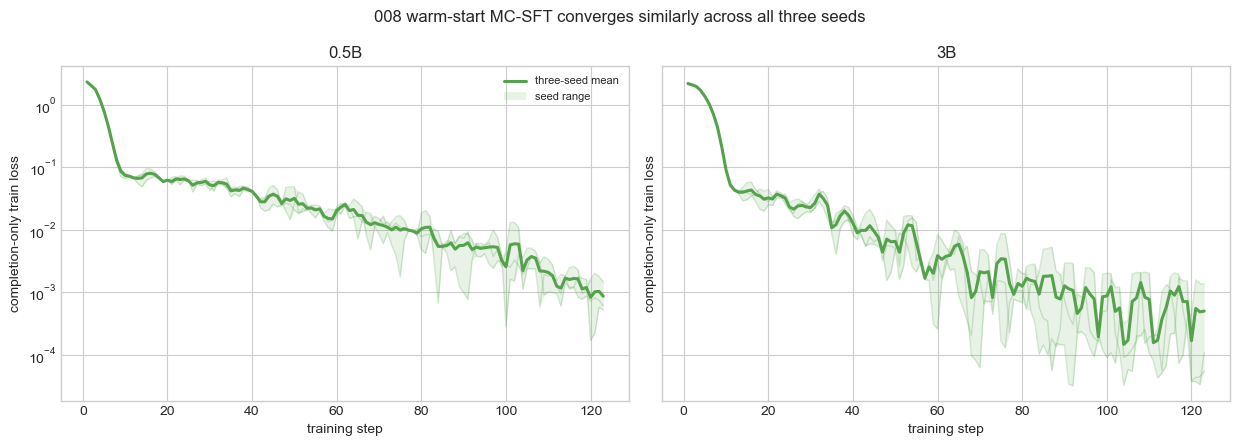

In [33]:
# plot the loss curve across all 123 MC-SFT steps and three seeds
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5), sharey=True)
for ax, scale in zip(axes, SCALES):
    seed_curves = []
    steps = None
    for seed in SEEDS:
        losses = [row for row in RUNS[scale][seed]["trainlog"] if "loss" in row and "step" in row]
        frame = pd.DataFrame(losses)
        steps = frame["step"].to_numpy()
        curve = frame["loss"].rolling(3, min_periods=1).mean().to_numpy()
        seed_curves.append(curve)
        ax.plot(steps, curve, color=COLORS["warm_sft"], alpha=0.25, lw=1)
    curves = np.vstack(seed_curves)
    ax.plot(steps, curves.mean(axis=0), color=COLORS["warm_sft"], lw=2.2, label="three-seed mean")
    ax.fill_between(steps, curves.min(axis=0), curves.max(axis=0),
                    color=COLORS["warm_sft"], alpha=0.13, linewidth=0, label="seed range")
    ax.set_yscale("log")
    ax.set_title(SCALE_LABELS[scale])
    ax.set_xlabel("training step")
    ax.set_ylabel("completion-only train loss")
axes[0].legend(fontsize=8)
fig.suptitle("008 warm-start MC-SFT converges similarly across all three seeds")
fig.tight_layout()
save(fig, "fig01_sft_loss_curves")
plt.show()


## 2. The complete preparation x MMLU-method comparison

The four main endpoints answer whether the GSM8K-SFT preparation helps both second-stage
methods in the same way. The untouched base and GSM8K-SFT-only endpoints are kept in the
table as context, but the interaction plot focuses on the two MMLU methods.


In [34]:
# calculate every generative endpoint with the current tier grouping
endpoint_rows = []
for scale in SCALES:
    for pathway in PATHWAYS:
        for group in GROUPS:
            endpoint_rows.append({
                "scale": scale,
                "pathway": pathway,
                "group": group,
                "accuracy": accuracy(ENDPOINTS[scale][pathway], group),
            })
endpoint_df = pd.DataFrame(endpoint_rows)
endpoint_pivot = endpoint_df.pivot_table(index=["scale", "pathway"], columns="group", values="accuracy")
display(endpoint_pivot.loc[[(scale, pathway) for scale in SCALES for pathway in PATHWAYS]].round(4))

multi_gen_rows = []
for scale in SCALES:
    sources = {
        "base_grpo": {0: ENDPOINTS[scale]["base_grpo"]},
        "base_sft": BASE_SFT_GEN[scale],
        "warm_grpo": WARM_GRPO_GEN[scale],
        "warm_sft": {seed: RUNS[scale][seed]["gen"] for seed in SEEDS},
    }
    for pathway, seed_rows in sources.items():
        for seed, rows in seed_rows.items():
            for group in GROUPS:
                multi_gen_rows.append({"scale": scale, "pathway": pathway, "seed": seed,
                                       "group": group, "accuracy": accuracy(rows, group)})
multi_gen_df = pd.DataFrame(multi_gen_rows)
multi_gen_summary = (multi_gen_df.groupby(["scale", "pathway", "group"])["accuracy"]
                     .agg(["mean", "std", "min", "max", "count"]).reset_index())
display(multi_gen_summary.set_index(["scale", "pathway", "group"]).round(4))


group              easy    hard  medium  overall
scale pathway                                   
B05   base       0.2218  0.1313  0.1675   0.1852
      gsm8k_sft  0.2389  0.1692  0.1905   0.2086
      base_grpo  0.4881  0.2551  0.3645   0.3992
      base_sft   0.6667  0.3712  0.4614   0.5382
      warm_grpo  0.5745  0.2449  0.4417   0.4623
      warm_sft   0.6621  0.3460  0.4729   0.5345
B3    base       0.6758  0.5076  0.5386   0.5961
      gsm8k_sft  0.6166  0.4394  0.4762   0.5340
      base_grpo  0.7770  0.5429  0.6190   0.6768
      base_sft   0.8510  0.5025  0.7110   0.7325
      warm_grpo  0.8294  0.5202  0.6798   0.7160
      warm_sft   0.8430  0.4697  0.7438   0.7325

mean     std     min     max  count
scale pathway   group                                         
B05   base_grpo easy     0.4881     NaN  0.4881  0.4881      1
                hard     0.2551     NaN  0.2551  0.2551      1
                medium   0.3645     NaN  0.3645  0.3645      1
                overall  0.3992     NaN  0.3992  0.3992      1
      base_sft  easy     0.6602  0.0056  0.6564  0.6667      3
                hard     0.3510  0.0191  0.3333  0.3712      3
                medium   0.4707  0.0081  0.4614  0.4762      3
                overall  0.5340  0.0040  0.5303  0.5382      3
      warm_grpo easy     0.5336  0.1389  0.3788  0.6473      3
                hard     0.2348  0.0116  0.2222  0.2449      3
                medium   0.4007  0.1024  0.2841  0.4762      3
                overall  0.4278  0.0999  0.3153  0.5058      3
      warm_sft  easy     0.6602  0.0033  0.6564  0.6621      3
                hard     0.3443  0.0102  0.3333  0.3535      3
                medium   0.4735  0.0074  0.4663  0.4811      3
                overall  0.5334  0.0014  0.5318  0.5345      3
B3    base_grpo easy     0.7770     NaN  0.7770  0.7770      1
                hard     0.5429     NaN  0.5429  0.5429      1
                medium   0.6190     NaN  0.6190  0.6190      1
                overall  0.6768     NaN  0.6768  0.6768      1
      base_sft  easy     0.8502  0.0007  0.8498  0.8510      3
                hard     0.5000  0.0216  0.4773  0.5202      3
                medium   0.7088  0.0019  0.7077  0.7110      3
                overall  0.7309  0.0047  0.7256  0.7346      3
      warm_grpo easy     0.8333  0.0056  0.8294  0.8373      2
                hard     0.5354  0.0214  0.5202  0.5505      2
                medium   0.6806  0.0012  0.6798  0.6814      2
                overall  0.7213  0.0075  0.7160  0.7266      2
      warm_sft  easy     0.8491  0.0063  0.8430  0.8555      3
                hard     0.4832  0.0154  0.4697  0.5000      3
                medium   0.7406  0.0033  0.7373  0.7438      3
                overall  0.7371  0.0040  0.7325  0.7394      3

saved fig02_factorial_generative_endpoints


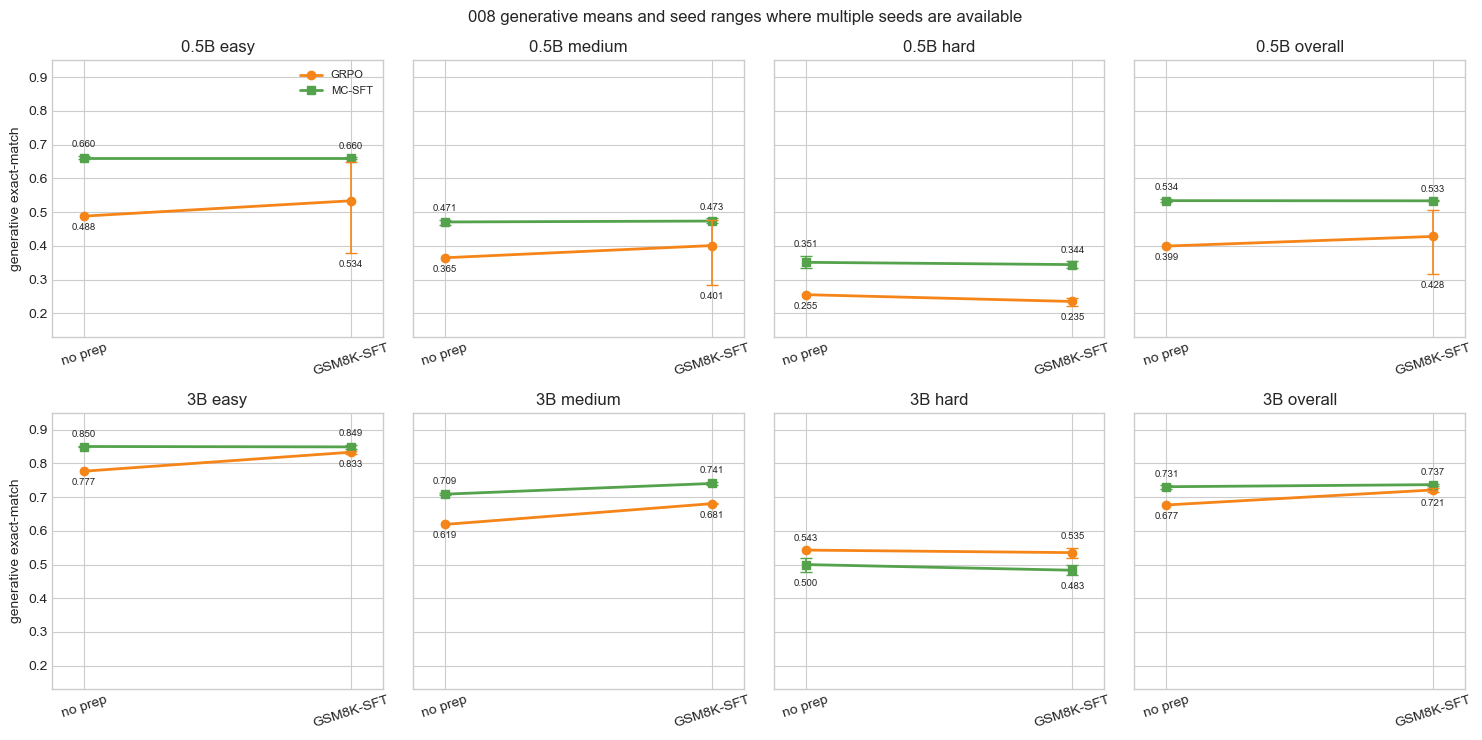

In [35]:
# show how the GSM8K warm start changes GRPO and MC-SFT separately
fig, axes = plt.subplots(2, 4, figsize=(15, 7.5), sharey=True)
for row_index, scale in enumerate(SCALES):
    for col_index, group in enumerate(GROUPS):
        ax = axes[row_index, col_index]
        parts = {pathway: multi_gen_summary[(multi_gen_summary["scale"] == scale) &
                                            (multi_gen_summary["pathway"] == pathway) &
                                            (multi_gen_summary["group"] == group)].iloc[0]
                 for pathway in ["base_grpo", "base_sft", "warm_grpo", "warm_sft"]}
        grpo_values = [parts["base_grpo"]["mean"], parts["warm_grpo"]["mean"]]
        sft_values = [parts["base_sft"]["mean"], parts["warm_sft"]["mean"]]
        ax.plot([0, 1], grpo_values, "o-", color=COLORS["warm_grpo"], lw=2, label="GRPO")
        ax.plot([0, 1], sft_values, "s-", color=COLORS["warm_sft"], lw=2, label="MC-SFT")
        for x_value, pathway in enumerate(["base_sft", "warm_sft"]):
            part = parts[pathway]
            ax.errorbar(x_value, part["mean"], yerr=[[part["mean"] - part["min"]],
                        [part["max"] - part["mean"]]], fmt="none", ecolor=COLORS["warm_sft"],
                        capsize=4, lw=1.2)
        warm_grpo = parts["warm_grpo"]
        if warm_grpo["count"] > 1:
            ax.errorbar(1, warm_grpo["mean"], yerr=[[warm_grpo["mean"] - warm_grpo["min"]],
                        [warm_grpo["max"] - warm_grpo["mean"]]], fmt="none",
                        ecolor=COLORS["warm_grpo"], capsize=4, lw=1.2)
        for x_value, (grpo_value, sft_value) in enumerate(zip(grpo_values, sft_values)):
            prep = 'base' if x_value == 0 else 'warm'
            high = max(parts[f'{prep}_grpo']['max'], parts[f'{prep}_sft']['max'])
            low = min(parts[f'{prep}_grpo']['min'], parts[f'{prep}_sft']['min'])
            for value, above in [(grpo_value, grpo_value >= sft_value),
                                 (sft_value, sft_value > grpo_value)]:
                edge = high if above else low
                ax.annotate(f'{value:.3f}', (x_value, edge), xytext=(0, 5 if above else -5),
                            textcoords='offset points', ha='center',
                            va='bottom' if above else 'top', fontsize=7)
        ax.margins(x=0.12)
        ax.set_xticks([0, 1])
        ax.set_xticklabels(["no prep", "GSM8K-SFT"], rotation=18)
        ax.set_title(f"{SCALE_LABELS[scale]} {group}")
        ax.set_ylim(0.13, 0.95)
        if col_index == 0:
            ax.set_ylabel("generative exact-match")
axes[0, 0].legend(fontsize=8)
fig.suptitle("008 generative means and seed ranges where multiple seeds are available")
fig.tight_layout()
save(fig, "fig02_factorial_generative_endpoints")
plt.show()


## 3. Paired item-level comparisons

The first contrast compares seed-0 MC-SFT and GRPO from the same GSM8K-SFT warm start. The next
two contrasts measure what the warm start changes inside each method. Bootstrap intervals
keep the 1,884 test items paired. McNemar tests use the same paired predictions. These are
artifact-level tests and are kept separate from the seed ranges above.


In [36]:
# calculate paired deltas, bootstrap intervals and McNemar tests
def paired_bootstrap(rows_a, rows_b, group, seed, n_boot=10000, batch=500):
    selected_a = rows_a if group == "overall" else [row for row in rows_a if row["tier"] == group]
    selected_b = rows_b if group == "overall" else [row for row in rows_b if row["tier"] == group]
    aligned(selected_a, selected_b)
    a = np.asarray([bool(row["correct"]) for row in selected_a], dtype=float)
    b = np.asarray([bool(row["correct"]) for row in selected_b], dtype=float)
    diffs = b - a
    rng = np.random.default_rng(seed)
    boot = np.empty(n_boot)
    for start in range(0, n_boot, batch):
        size = min(batch, n_boot - start)
        indices = rng.integers(0, len(diffs), size=(size, len(diffs)))
        boot[start:start + size] = diffs[indices].mean(axis=1)
    a_only = int(np.sum((a == 1) & (b == 0)))
    b_only = int(np.sum((a == 0) & (b == 1)))
    return {
        "delta": float(diffs.mean()),
        "ci_lo": float(np.percentile(boot, 2.5)),
        "ci_hi": float(np.percentile(boot, 97.5)),
        "a_only": a_only,
        "b_only": b_only,
        "mcnemar_p": mcnemar_exact(a_only, b_only),
    }

CONTRASTS = {
    "method_same_warm": ("warm_grpo", "warm_sft"),
    "warm_effect_sft": ("base_sft", "warm_sft"),
    "warm_effect_grpo": ("base_grpo", "warm_grpo"),
}
contrast_rows = []
for scale_index, scale in enumerate(SCALES):
    for contrast_index, (contrast, (path_a, path_b)) in enumerate(CONTRASTS.items()):
        for group_index, group in enumerate(GROUPS):
            result = paired_bootstrap(
                ENDPOINTS[scale][path_a], ENDPOINTS[scale][path_b], group,
                seed=800 + scale_index * 100 + contrast_index * 10 + group_index,
            )
            contrast_rows.append({"scale": scale, "contrast": contrast, "group": group, **result})
contrast_df = pd.DataFrame(contrast_rows)
contrast_df["holm_p_tiers"] = np.nan
for scale in SCALES:
    for contrast in CONTRASTS:
        mask = ((contrast_df["scale"] == scale) & (contrast_df["contrast"] == contrast) &
                (contrast_df["group"] != "overall"))
        contrast_df.loc[mask, "holm_p_tiers"] = holm(contrast_df.loc[mask, "mcnemar_p"].tolist())

contrast_tbl = contrast_df.copy()
contrast_tbl["scale"] = contrast_tbl["scale"].map(SCALE_LABELS)
display(contrast_tbl.set_index(["scale", "contrast", "group"])
        [["delta", "ci_lo", "ci_hi", "a_only", "b_only", "mcnemar_p", "holm_p_tiers"]]
        .round({"delta": 4, "ci_lo": 4, "ci_hi": 4, "mcnemar_p": 8, "holm_p_tiers": 8}))


delta   ci_lo   ci_hi  a_only  b_only  \
scale contrast         group                                             
0.5B  method_same_warm easy     0.0876  0.0546  0.1195      70     147   
                       medium   0.0312 -0.0066  0.0706      64      83   
                       hard     0.1010  0.0480  0.1540      40      80   
                       overall  0.0722  0.0494  0.0950     174     310   
      warm_effect_sft  easy    -0.0046 -0.0228  0.0137      34      30   
                       medium   0.0115 -0.0099  0.0328      20      27   
                       hard    -0.0253 -0.0631  0.0152      35      25   
                       overall -0.0037 -0.0175  0.0101      89      82   
      warm_effect_grpo easy     0.0865  0.0478  0.1251     121     197   
                       medium   0.0772  0.0312  0.1248      83     130   
                       hard    -0.0101 -0.0657  0.0455      64      60   
                       overall  0.0632  0.0361  0.0892     268     387   
3B    method_same_warm easy     0.0137 -0.0080  0.0353      43      55   
                       medium   0.0640  0.0328  0.0969      29      68   
                       hard    -0.0505 -0.1111  0.0076      83      63   
                       overall  0.0165 -0.0027  0.0361     155     186   
      warm_effect_sft  easy    -0.0080 -0.0216  0.0046      21      14   
                       medium   0.0328  0.0115  0.0558      14      34   
                       hard    -0.0328 -0.0707  0.0051      35      22   
                       overall  0.0000 -0.0117  0.0122      70      70   
      warm_effect_grpo easy     0.0523  0.0273  0.0774      44      90   
                       medium   0.0608  0.0263  0.0952      41      78   
                       hard    -0.0227 -0.0783  0.0328      67      58   
                       overall  0.0393  0.0191  0.0600     152     226   

                                   mcnemar_p  holm_p_tiers  
scale contrast         group                                
0.5B  method_same_warm easy     1.900000e-07  5.600000e-07  
                       medium   1.373778e-01  1.373778e-01  
                       hard     3.304000e-04  6.608000e-04  
                       overall  0.000000e+00           NaN  
      warm_effect_sft  easy     7.079808e-01  7.633868e-01  
                       medium   3.816934e-01  7.633868e-01  
                       hard     2.450608e-01  7.351825e-01  
                       overall  6.464833e-01           NaN  
      warm_effect_grpo easy     2.394000e-05  7.182000e-05  
                       medium   1.561130e-03  3.122270e-03  
                       hard     7.877466e-01  7.877466e-01  
                       overall  3.790000e-06           NaN  
3B    method_same_warm easy     2.664056e-01  2.664056e-01  
                       medium   9.341000e-05  2.802200e-04  
                       hard     1.155397e-01  2.310794e-01  
                       overall  1.041109e-01           NaN  
      warm_effect_sft  easy     3.105047e-01  3.105047e-01  
                       medium   5.515200e-03  1.654560e-02  
                       hard     1.111611e-01  2.223222e-01  
                       overall  1.000000e+00           NaN  
      warm_effect_grpo easy     8.745000e-05  2.623600e-04  
                       medium   8.881400e-04  1.776270e-03  
                       hard     4.744216e-01  4.744216e-01  
                       overall  1.660800e-04           NaN

saved fig03_warm_sft_vs_warm_grpo


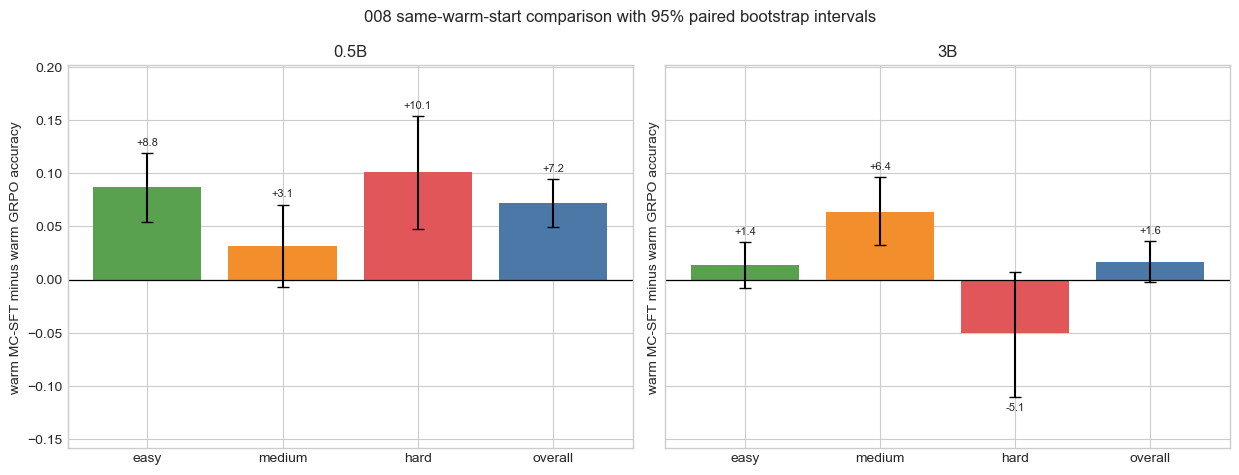

In [37]:
# compare warm-start MC-SFT directly against warm-start GRPO
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), sharey=True)
x = np.arange(len(GROUPS))
for ax, scale in zip(axes, SCALES):
    part = (contrast_df[(contrast_df["scale"] == scale) &
                        (contrast_df["contrast"] == "method_same_warm")]
            .set_index("group").loc[GROUPS])
    values = part["delta"].to_numpy()
    errors = np.vstack([values - part["ci_lo"].to_numpy(), part["ci_hi"].to_numpy() - values])
    bars = ax.bar(x, values, yerr=errors, capsize=4, color=[TIER_COLORS[group] for group in GROUPS])
    labels = [f"{value * 100:+.1f}" for value in values]
    ax.bar_label(bars, labels=labels, padding=4, fontsize=8)
    ax.margins(y=0.18)
    ax.axhline(0, color="black", lw=0.9)
    ax.set_xticks(x)
    ax.set_xticklabels(GROUPS)
    ax.set_title(SCALE_LABELS[scale])
    ax.set_ylabel("warm MC-SFT minus warm GRPO accuracy")
fig.suptitle("008 same-warm-start comparison with 95% paired bootstrap intervals")
fig.tight_layout()
save(fig, "fig03_warm_sft_vs_warm_grpo")
plt.show()


saved fig04_warm_start_effect_by_method


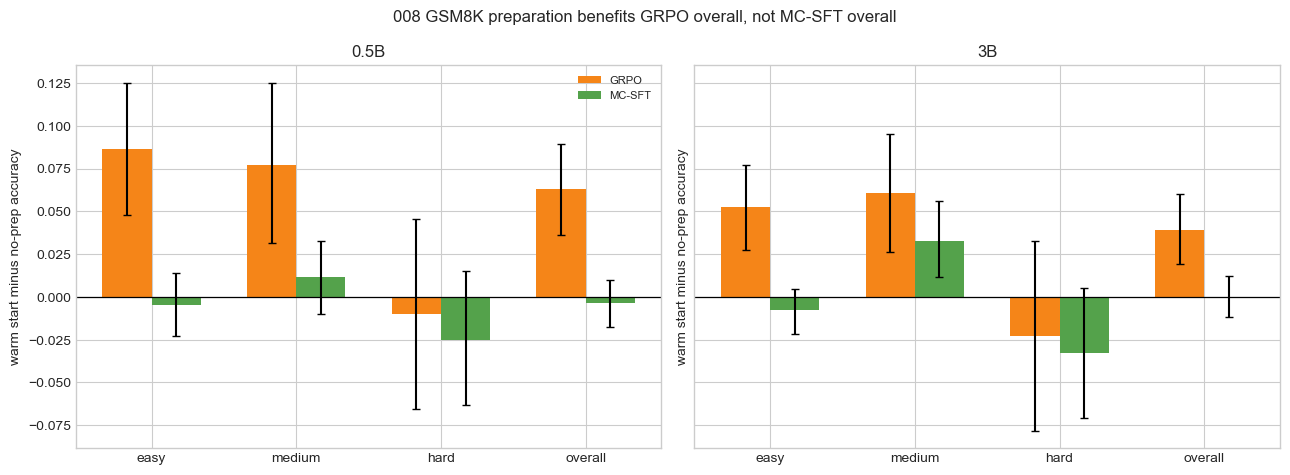

In [38]:
# compare the effect of GSM8K-SFT preparation inside each MMLU method
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
x = np.arange(len(GROUPS))
width = 0.34
for ax, scale in zip(axes, SCALES):
    for index, (contrast, label, color) in enumerate([
        ("warm_effect_grpo", "GRPO", COLORS["warm_grpo"]),
        ("warm_effect_sft", "MC-SFT", COLORS["warm_sft"]),
    ]):
        part = (contrast_df[(contrast_df["scale"] == scale) &
                            (contrast_df["contrast"] == contrast)]
                .set_index("group").loc[GROUPS])
        values = part["delta"].to_numpy()
        errors = np.vstack([values - part["ci_lo"].to_numpy(), part["ci_hi"].to_numpy() - values])
        positions = x + (index - 0.5) * width
        ax.bar(positions, values, width, yerr=errors, capsize=3, color=color, label=label)
    ax.axhline(0, color="black", lw=0.9)
    ax.set_xticks(x)
    ax.set_xticklabels(GROUPS)
    ax.set_title(SCALE_LABELS[scale])
    ax.set_ylabel("warm start minus no-prep accuracy")
axes[0].legend(fontsize=8)
fig.suptitle("008 GSM8K preparation benefits GRPO overall, not MC-SFT overall")
fig.tight_layout()
save(fig, "fig04_warm_start_effect_by_method")
plt.show()


## 4. Three-seed knowledge probe

MC-SFT has three stage-two probe seeds at each scale. GRPO has three seeds at 0.5B and two
at 3B. Plotting change from the shared base probe keeps the small movements visible without mixing
them with the much larger generative gains.


In [39]:
# calculate probe changes from the shared base for every available seed
probe_rows = []
for scale in SCALES:
    for group in GROUPS:
        base_value = accuracy(PROBE_REFS[scale]["base"], group)
        for seed, rows in PROBE_REFS[scale]["warm_grpo"].items():
            probe_rows.append({"scale": scale, "method": "warm_grpo", "seed": seed, "group": group,
                               "delta": accuracy(rows, group) - base_value})
        for method in ["base_sft", "warm_sft"]:
            for seed in SEEDS:
                probe_rows.append({"scale": scale, "method": method, "seed": seed, "group": group,
                                   "delta": accuracy(PROBE_REFS[scale][method][seed], group) - base_value})
probe_df = pd.DataFrame(probe_rows)
probe_summary = (probe_df.groupby(["scale", "method", "group"])["delta"]
                 .agg(["mean", "std", "min", "max"]).reset_index())
display(probe_summary.assign(scale=probe_summary["scale"].map(SCALE_LABELS))
        .set_index(["scale", "method", "group"]).round(4))


mean     std     min     max
scale method    group                                  
0.5B  base_sft  easy    -0.0102  0.0030 -0.0137 -0.0080
                hard    -0.0227  0.0025 -0.0253 -0.0202
                medium  -0.0033  0.0072 -0.0082  0.0049
                overall -0.0106  0.0030 -0.0133 -0.0074
      warm_grpo easy    -0.0030  0.0040 -0.0068  0.0011
                hard    -0.0093  0.0114 -0.0202  0.0025
                medium   0.0000  0.0072 -0.0049  0.0082
                overall -0.0034  0.0041 -0.0069  0.0011
      warm_sft  easy    -0.0004  0.0013 -0.0011  0.0011
                hard    -0.0438  0.0148 -0.0606 -0.0328
                medium  -0.0049  0.0033 -0.0082 -0.0016
                overall -0.0110  0.0035 -0.0149 -0.0080
3B    base_sft  easy     0.0061  0.0013  0.0046  0.0068
                hard     0.0244  0.0053  0.0202  0.0303
                medium   0.0038  0.0034  0.0000  0.0066
                overall  0.0092  0.0006  0.0085  0.0096
      warm_grpo easy     0.0011  0.0048 -0.0023  0.0046
                hard     0.0051  0.0000  0.0051  0.0051
                medium   0.0090  0.0012  0.0082  0.0099
                overall  0.0045  0.0026  0.0027  0.0064
      warm_sft  easy    -0.0015  0.0024 -0.0034  0.0011
                hard     0.0328  0.0044  0.0303  0.0379
                medium   0.0137  0.0019  0.0115  0.0148
                overall  0.0106  0.0024  0.0085  0.0133

saved fig05_probe_delta_from_base


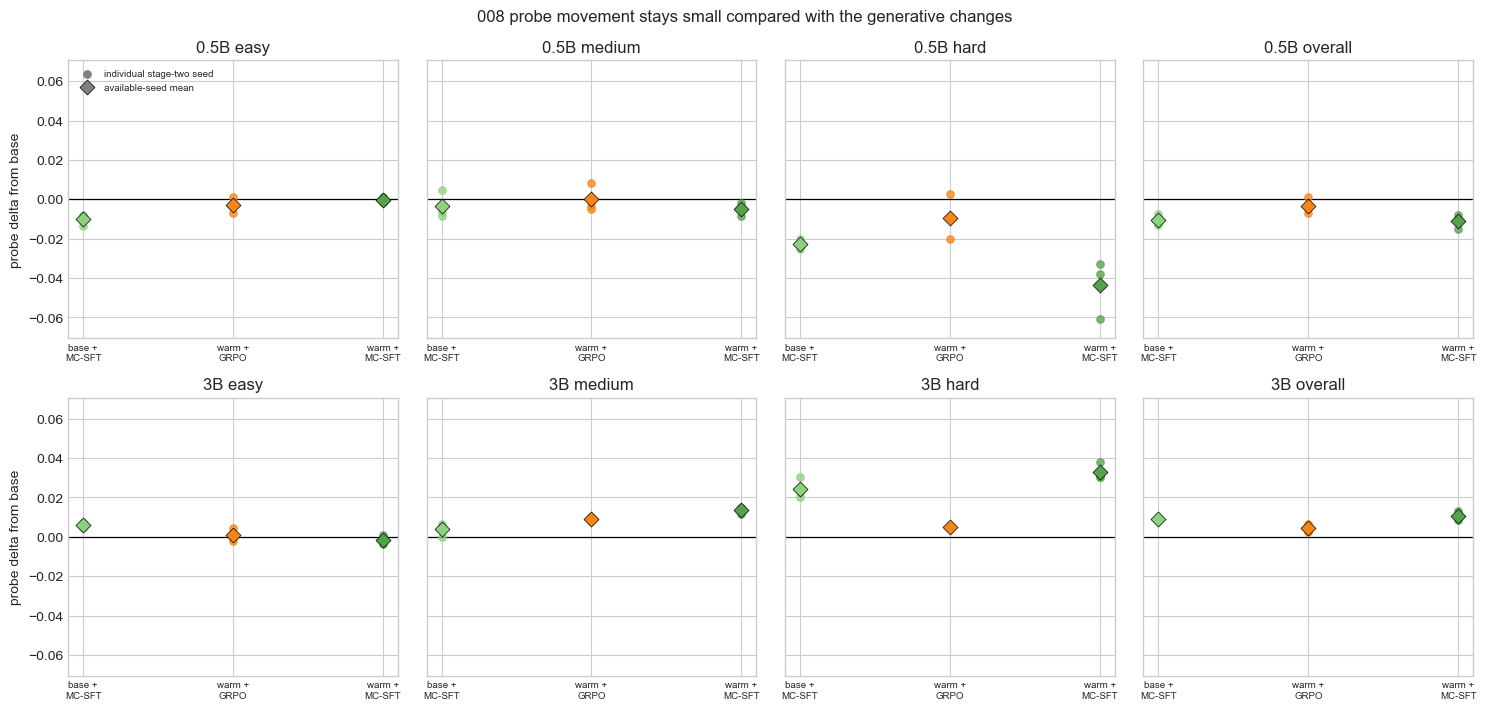

In [40]:
# plot the available probe seeds and their means
methods = ["base_sft", "warm_grpo", "warm_sft"]
labels = ["base +\nMC-SFT", "warm +\nGRPO", "warm +\nMC-SFT"]
fig, axes = plt.subplots(2, 4, figsize=(15, 7.2), sharey=True)
all_limit = max(0.07, probe_df["delta"].abs().max() + 0.01)
for row_index, scale in enumerate(SCALES):
    for col_index, group in enumerate(GROUPS):
        ax = axes[row_index, col_index]
        for x_value, method in enumerate(methods):
            part = probe_df[(probe_df["scale"] == scale) &
                            (probe_df["group"] == group) &
                            (probe_df["method"] == method)]
            values = part["delta"].to_numpy()
            color = COLORS[method]
            ax.scatter(np.full(len(values), x_value), values, color=color, s=28, alpha=0.75, zorder=3)
            ax.scatter([x_value], [values.mean()], color=color, marker="D", s=58,
                       edgecolor="black", linewidth=0.5, zorder=4)
        ax.axhline(0, color="black", lw=0.9)
        ax.set_xticks(np.arange(len(methods)))
        ax.set_xticklabels(labels, fontsize=7)
        ax.set_ylim(-all_limit, all_limit)
        ax.set_title(f"{SCALE_LABELS[scale]} {group}")
        if col_index == 0:
            ax.set_ylabel("probe delta from base")
axes[0, 0].scatter([], [], color="grey", s=28, label="individual stage-two seed")
axes[0, 0].scatter([], [], color="grey", marker="D", s=58, edgecolor="black",
                   linewidth=0.5, label="available-seed mean")
axes[0, 0].legend(fontsize=7, loc="upper left")
fig.suptitle("008 probe movement stays small compared with the generative changes")
fig.tight_layout()
save(fig, "fig05_probe_delta_from_base")
plt.show()


## 5. Subject pattern and output behaviour

The subject matrix checks whether the tier conclusions come from one isolated subject.
The diagnostic plot checks whether the methods reached accuracy through the same kind of
output behaviour.


saved fig06_subject_accuracy_matrix


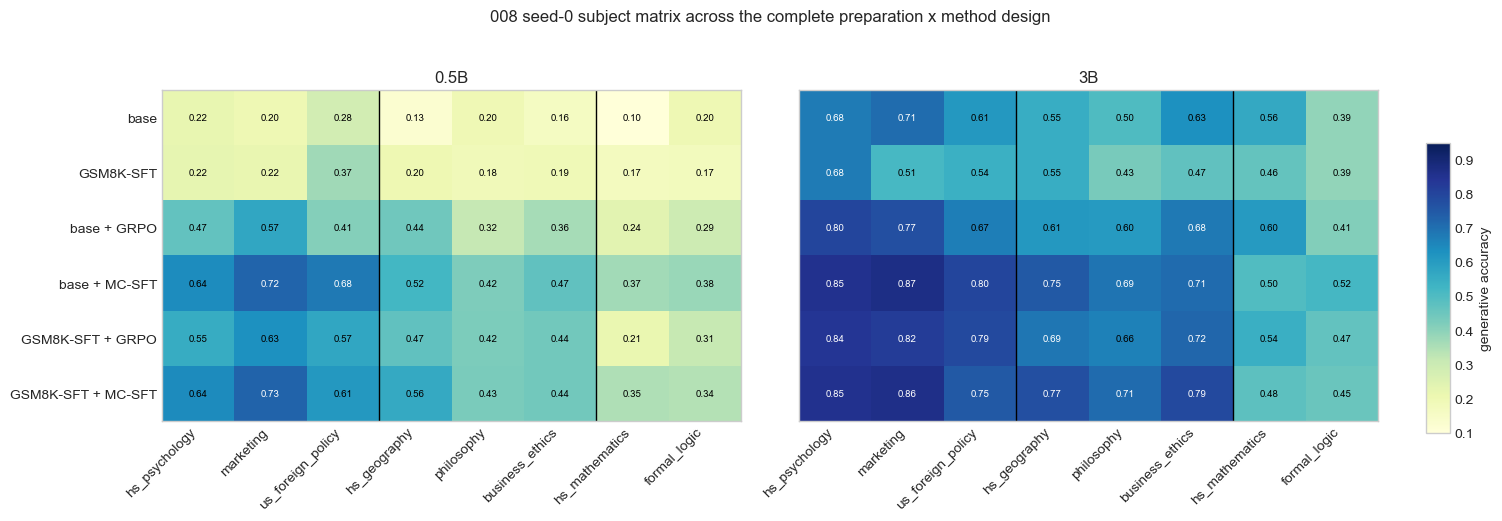

In [41]:
# compare every stage and method in one subject matrix without heatmap seams
fig, axes = plt.subplots(1, 2, figsize=(16, 5.8))
for panel_index, (ax, scale) in enumerate(zip(axes, SCALES)):
    matrix = np.array([
        [subject_accuracy(ENDPOINTS[scale][pathway])[subject] for subject in SUBJECTS]
        for pathway in PATHWAYS
    ])
    image = ax.imshow(matrix, cmap="YlGnBu", vmin=0.1, vmax=0.95,
                      aspect="auto", interpolation="nearest")
    ax.set_xticks(np.arange(len(SUBJECTS)))
    ax.set_xticklabels(SHORT_SUBJECTS, rotation=45, ha="right")
    ax.set_yticks(np.arange(len(PATHWAYS)))
    if panel_index == 0:
        ax.set_yticklabels([PATHWAY_LABELS[pathway] for pathway in PATHWAYS])
    else:
        ax.set_yticklabels([])
        ax.tick_params(axis="y", length=0)
    ax.set_title(SCALE_LABELS[scale])
    ax.grid(False)
    ax.axvline(2.5, color="black", lw=1)
    ax.axvline(5.5, color="black", lw=1)
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            color = heatmap_text_color(image, matrix[i, j])
            ax.text(j, i, f"{matrix[i, j]:.2f}", ha="center", va="center", fontsize=7, color=color)
cbar_axis = fig.add_axes([0.91, 0.25, 0.015, 0.5])
fig.colorbar(image, cax=cbar_axis, label="generative accuracy")
fig.suptitle("008 seed-0 subject matrix across the complete preparation x method design")
fig.subplots_adjust(left=0.12, right=0.88, bottom=0.27, top=0.84, wspace=0.10)
save(fig, "fig06_subject_accuracy_matrix")
plt.show()


format_compliance  extraction_failure  mean_length
scale pathway                                                               
0.5B  base + GRPO                    0.0175              0.0823     269.2792
      base + MC-SFT                  0.9830              0.0000      15.9050
      GSM8K-SFT + GRPO               0.9406              0.0366      65.8455
      GSM8K-SFT + MC-SFT             0.9751              0.0000      16.2686
3B    base + GRPO                    0.9374              0.0494     119.5042
      base + MC-SFT                  1.0000              0.0000      16.0000
      GSM8K-SFT + GRPO               0.9644              0.0297      73.7001
      GSM8K-SFT + MC-SFT             1.0000              0.0000      16.0000

saved fig07_output_diagnostics


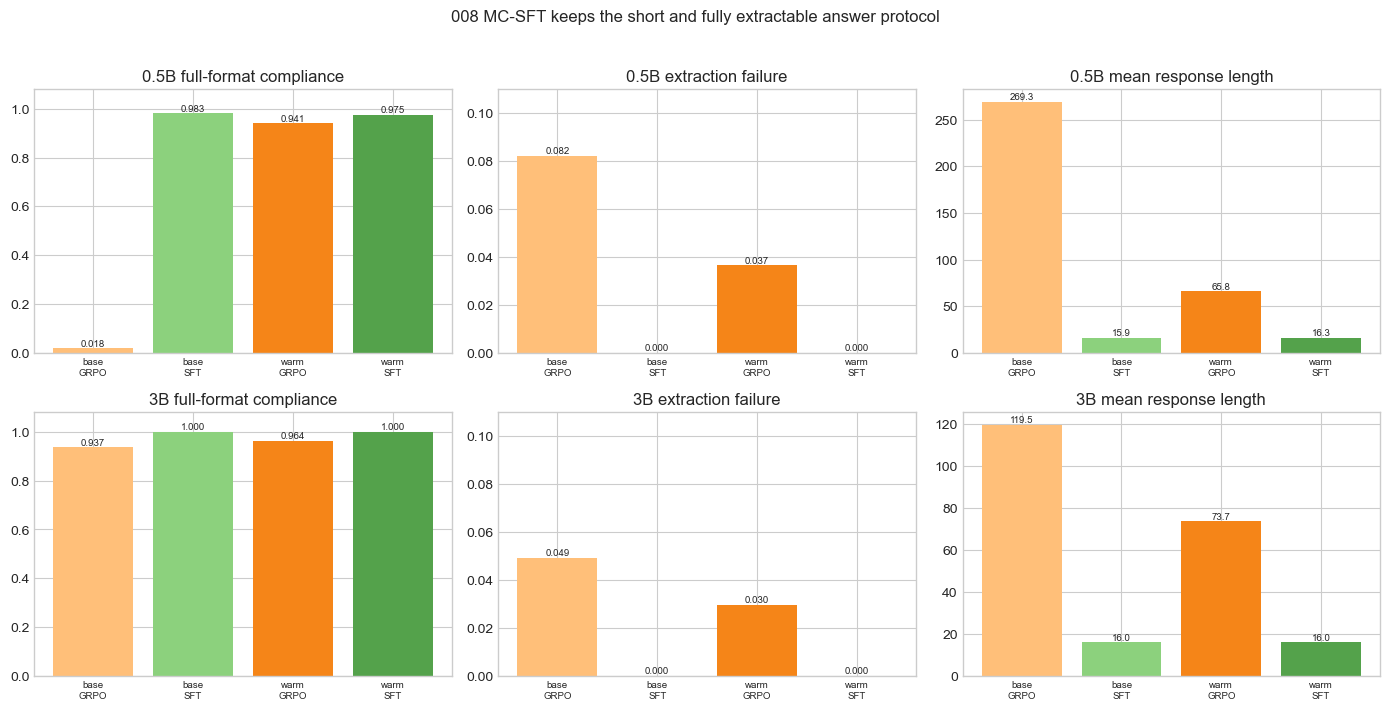

In [42]:
# compare seed-0 format, extraction and response length for the four MMLU endpoints
diagnostic_pathways = ["base_grpo", "base_sft", "warm_grpo", "warm_sft"]
diagnostic_rows = []
for scale in SCALES:
    for pathway in diagnostic_pathways:
        diagnostic_rows.append({"scale": scale, "pathway": pathway,
                                **diagnosis(ENDPOINTS[scale][pathway])})
diagnostic_df = pd.DataFrame(diagnostic_rows)
display(diagnostic_df.assign(scale=diagnostic_df["scale"].map(SCALE_LABELS),
                             pathway=diagnostic_df["pathway"].map(PATHWAY_LABELS))
        .set_index(["scale", "pathway"]).round(4))

fig, axes = plt.subplots(2, 3, figsize=(14, 7.2))
metric_specs = [
    ("format_compliance", "full-format compliance", (0, 1.08)),
    ("extraction_failure", "extraction failure", (0, 0.11)),
    ("mean_length", "mean response length", None),
]
for row_index, scale in enumerate(SCALES):
    part = diagnostic_df[diagnostic_df["scale"] == scale].set_index("pathway").loc[diagnostic_pathways]
    for col_index, (metric, title, limits) in enumerate(metric_specs):
        ax = axes[row_index, col_index]
        values = part[metric].to_numpy()
        bars = ax.bar(np.arange(len(diagnostic_pathways)), values,
                      color=[COLORS[pathway] for pathway in diagnostic_pathways])
        for bar, value in zip(bars, values):
            label = f"{value:.1f}" if metric == "mean_length" else f"{value:.3f}"
            ax.text(bar.get_x() + bar.get_width() / 2, value, label,
                    ha="center", va="bottom", fontsize=7)
        ax.set_xticks(np.arange(len(diagnostic_pathways)))
        ax.set_xticklabels(["base\nGRPO", "base\nSFT", "warm\nGRPO", "warm\nSFT"], fontsize=7)
        ax.set_title(f"{SCALE_LABELS[scale]} {title}")
        if limits:
            ax.set_ylim(*limits)
fig.suptitle("008 MC-SFT keeps the short and fully extractable answer protocol")
fig.tight_layout(rect=[0, 0, 1, 0.96])
save(fig, "fig07_output_diagnostics")
plt.show()


## 6. Tier-grouping sensitivity

Business ethics and US foreign policy swap between the proposal and validated groupings.
The hard tier is unchanged. The main method contrast is recalculated under both definitions.


In [43]:
# check whether the tier update changes the warm MC-SFT versus warm GRPO result
sensitivity_rows = []
for scale in SCALES:
    for group in ["easy", "medium", "hard"]:
        values = {}
        for label, grouping in [("validated", VALIDATED_TIERS), ("proposal", TIERS_PROPOSAL)]:
            grpo_rows = retag(ENDPOINTS[scale]["warm_grpo"], grouping)
            sft_rows = retag(ENDPOINTS[scale]["warm_sft"], grouping)
            values[label] = accuracy(sft_rows, group) - accuracy(grpo_rows, group)
        sensitivity_rows.append({
            "scale": SCALE_LABELS[scale],
            "tier": group,
            "validated_delta": values["validated"],
            "proposal_delta": values["proposal"],
            "difference": values["validated"] - values["proposal"],
        })
sensitivity_tbl = pd.DataFrame(sensitivity_rows).set_index(["scale", "tier"])
display(sensitivity_tbl.round(4))
print("largest absolute change from tier definition:",
      f"{sensitivity_tbl['difference'].abs().max() * 100:.2f} percentage points")


validated_delta  proposal_delta  difference
scale tier                                               
0.5B  easy             0.0876          0.0830      0.0046
      medium           0.0312          0.0378     -0.0066
      hard             0.1010          0.1010      0.0000
3B    easy             0.0137          0.0262     -0.0125
      medium           0.0640          0.0460      0.0181
      hard            -0.0505         -0.0505      0.0000

largest absolute change from tier definition: 1.81 percentage points


## 7. Compact result table and cross-referenced conclusion


In [44]:
# keep the seed-0 paired effects and available-seed generative summaries together
headline_rows = []
for scale in SCALES:
    main = contrast_df[(contrast_df["scale"] == scale) &
                       (contrast_df["contrast"] == "method_same_warm") &
                       (contrast_df["group"] == "overall")].iloc[0]
    sft_warm = contrast_df[(contrast_df["scale"] == scale) &
                           (contrast_df["contrast"] == "warm_effect_sft") &
                           (contrast_df["group"] == "overall")].iloc[0]
    grpo_warm = contrast_df[(contrast_df["scale"] == scale) &
                            (contrast_df["contrast"] == "warm_effect_grpo") &
                            (contrast_df["group"] == "overall")].iloc[0]
    warm_probe = probe_summary[(probe_summary["scale"] == scale) &
                               (probe_summary["method"] == "warm_sft") &
                               (probe_summary["group"] == "overall")].iloc[0]
    warm_sft_gen = multi_gen_summary[(multi_gen_summary["scale"] == scale) &
                                     (multi_gen_summary["pathway"] == "warm_sft") &
                                     (multi_gen_summary["group"] == "overall")].iloc[0]
    warm_grpo_gen = multi_gen_summary[(multi_gen_summary["scale"] == scale) &
                                      (multi_gen_summary["pathway"] == "warm_grpo") &
                                      (multi_gen_summary["group"] == "overall")].iloc[0]
    base_sft_gen = multi_gen_summary[(multi_gen_summary["scale"] == scale) &
                                     (multi_gen_summary["pathway"] == "base_sft") &
                                     (multi_gen_summary["group"] == "overall")].iloc[0]
    diagnostic_values = [diagnosis(RUNS[scale][seed]["gen"]) for seed in SEEDS]
    diagnostics = {key: np.mean([row[key] for row in diagnostic_values]) for key in diagnostic_values[0]}
    headline_rows.append({
        "scale": SCALE_LABELS[scale],
        "warm_grpo_gen_seed0": accuracy(ENDPOINTS[scale]["warm_grpo"]),
        "warm_mc_sft_gen_seed0": accuracy(ENDPOINTS[scale]["warm_sft"]),
        "paired_seed0_mc_sft_minus_grpo": main["delta"],
        "main_ci_lo": main["ci_lo"],
        "main_ci_hi": main["ci_hi"],
        "main_mcnemar_p": main["mcnemar_p"],
        "warm_effect_grpo": grpo_warm["delta"],
        "warm_effect_mc_sft": sft_warm["delta"],
        "warm_mc_sft_gen_mean_3_seeds": warm_sft_gen["mean"],
        "warm_mc_sft_gen_std_3_seeds": warm_sft_gen["std"],
        "warm_mc_sft_gen_min": warm_sft_gen["min"],
        "warm_mc_sft_gen_max": warm_sft_gen["max"],
        "warm_grpo_gen_mean_available": warm_grpo_gen["mean"],
        "warm_grpo_gen_seed_count": warm_grpo_gen["count"],
        "descriptive_mean_gap": warm_sft_gen["mean"] - warm_grpo_gen["mean"],
        "mc_sft_warm_effect_mean_3_seeds": warm_sft_gen["mean"] - base_sft_gen["mean"],
        "warm_mc_sft_probe_mean_3_seeds": warm_probe["mean"],
        "warm_mc_sft_probe_std_3_seeds": warm_probe["std"],
        **diagnostics,
    })
headline_tbl = pd.DataFrame(headline_rows).set_index("scale")
display(headline_tbl.round(4))


,warm_grpo_gen_seed0,warm_mc_sft_gen_seed0,paired_seed0_mc_sft_minus_grpo,main_ci_lo,main_ci_hi,main_mcnemar_p,warm_effect_grpo,warm_effect_mc_sft,warm_mc_sft_gen_mean_3_seeds,warm_mc_sft_gen_std_3_seeds,...,warm_mc_sft_gen_max,warm_grpo_gen_mean_available,warm_grpo_gen_seed_count,descriptive_mean_gap,mc_sft_warm_effect_mean_3_seeds,warm_mc_sft_probe_mean_3_seeds,warm_mc_sft_probe_std_3_seeds,format_compliance,extraction_failure,mean_length
scale,,,,,,,,,,,,,,,,,,,,,
0.5B,0.4623,0.5345,0.0722,0.0494,0.0950,0.0000,0.0632,-0.0037,0.5334,0.0014,...,0.5345,0.4278,3,0.1056,-0.0005,-0.0110,0.0035,0.9917,0.0,16.0708
3B,0.7160,0.7325,0.0165,-0.0027,0.0361,0.1041,0.0393,0.0000,0.7371,0.0040,...,0.7394,0.7213,2,0.0157,0.0062,0.0106,0.0024,1.0000,0.0,16.0000


## Cross-referenced conclusion

All six 008 training runs, all six probes and all six generative evaluations finished correctly.
For the exactly matched seed-0 artifacts, MC-SFT is **+7.2 points**
above GRPO at 0.5B, with an item-level 95% interval of
**[+4.9, +9.5]**. At 3B the overall difference is
**+1.6 points**, with interval
**[-0.3, +3.6]**, so the two saved seed-0 endpoints
are not clearly separated overall. These item-level intervals remain conditional on seed 0.

The extra evaluations show that MC-SFT itself is stable. Warm MC-SFT ranges only from
**53.2% to 53.5%** at 0.5B and from
**73.2% to 73.9%** at 3B. The two available 3B GRPO
endpoints range from **71.6% to 72.7%**. MC-SFT is
**+10.6 points** relative to the three-seed 0.5B GRPO mean and
**+1.6 points** relative to the two-seed 3B GRPO mean. These are descriptive
procedure-level sensitivity comparisons, not paired tests across matching seeds.

The full 2 x 2 result confirms the main reason for running 008. Adding GSM8K-SFT changes
MC-SFT overall by only **-0.1 points** at 0.5B and
**+0.6 points** at 3B using the three-seed means. The same
preparation improves the matched seed-0 GRPO artifacts by
**+6.3** and **+3.9 points**. In this setup,
the warm start is useful for GRPO but redundant for MC-SFT overall. This directly supports
the interpretation proposed after 007 rather than only inferring it from separate runs.

The 3B tier split is still important. In the matched seed-0 comparison, warm MC-SFT is
**+6.4 points** above warm GRPO on medium, but
**-5.1 points** on hard. The hard interval is
**[-11.1, +0.8]**, so GRPO keeps a directional hard-tier
advantage but this seed-0 artifact does not resolve it statistically. At 0.5B MC-SFT is
above GRPO even on hard, so there is no matching small-scale exception. Across the available
generative seeds, the hard-tier mean differences are **+10.9 points** at
0.5B and **-5.2 points** at 3B.

The probe results stay close to the pattern from 007, while MC-SFT again produces
roughly 16-token answers with near-perfect format and no extraction failures. This keeps
the main mechanism interpretation: most of the large generative movement is answer
expression and protocol learning, not a similarly large shift in the letter preference.

The remaining limits matter. The GSM8K warm-start adapter is fixed at seed 0 for all 008
stage-two seeds, and the comparison keeps method-specific optimisation choices. The paired
tests and the complete 2 x 2 matrix are still seed-0 artifact comparisons.
The 3B GRPO references used an earlier A100 80GB runtime while 007/008 used A100 40GB,
although all were A100 BF16 runs. The second 3B GRPO endpoint strengthens the procedure
sensitivity check, but one extra seed does not turn the seed-0 hard-tier paired contrast into a
fully matched multi-seed method comparison.
